
#1. Project Overview


In this project, we will build a machine learning model to predict whether a customer is likely to leave a company or continue using its services.

We will first understand the customer data, clean and explore it, and identify the factors that may be related to customer churn. After that, we will train and compare different machine learning models and select the one that performs best.

The final goal is to help a company identify customers who may leave, so that it can take steps to retain them.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df = pd.read_csv("/content/WA_Fn-UseC_-Telco-Customer-Churn.csv")

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2. Understanding the Dataset

In [ ]:
print("Dataset Shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset Shape: (7043, 21)
Number of rows: 7043
Number of columns: 21


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## 3. Data Cleaning

In [ ]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [ ]:
df["TotalCharges"].value_counts().head(10)

,count
TotalCharges,
,11
20.2,11
19.75,9
20.05,8
19.9,8
19.65,8
19.55,7
45.3,7
20.15,6


In [ ]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [ ]:
df["TotalCharges"].isnull().sum()

np.int64(11)

In [ ]:
missing_count = df["TotalCharges"].isnull().sum()
total_rows = len(df)

print("Missing TotalCharges:", missing_count)
print("Percentage of missing values:", round((missing_count / total_rows) * 100, 2), "%")

Missing TotalCharges: 11
Percentage of missing values: 0.16 %


In [ ]:
df[df['TotalCharges'].isnull()][['tenure', 'MonthlyCharges', 'TotalCharges']]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [ ]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)
print("Missing TotalCharges:", df["TotalCharges"].isnull().sum())

Missing TotalCharges: 0


In [ ]:
df["TotalCharges"].dtype

dtype('float64')

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df["customerID"].nunique()

7043

In [ ]:
df.nunique().sort_values()

,0
gender,2
SeniorCitizen,2
Partner,2
Dependents,2
PhoneService,2
PaperlessBilling,2
Churn,2
MultipleLines,3
TechSupport,3
StreamingTV,3


In [ ]:
df = df.drop('customerID', axis=1)
print("New shape:", df.shape)

New shape: (7043, 20)


In [ ]:
for col in df.select_dtypes(include="object").columns:
    blank_count = (df[col].str.strip() == "").sum()
    if blank_count > 0:
        print(f"{col}: {blank_count} blank values")

In [ ]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    if (df[col] < 0).any():
        print(f"{col}: negative values found")

## 4. Exploratory Data Analysis (EDA)

In [ ]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


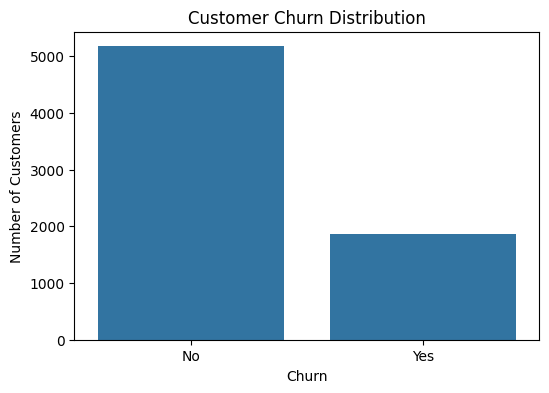

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")

plt.show()

### Insight

The dataset contains more customers who stayed with the company than those who left. Around 26.6% of customers have churned, which shows that customer churn is an important problem that the company should focus on.

In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe()

,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


### Statistical Insights

The average customer tenure is around 32 months, while the median tenure is 29 months. The average monthly charge is about 64.76, and the median is 70.35.

TotalCharges has a noticeably higher mean than median, suggesting that the distribution may be right-skewed.

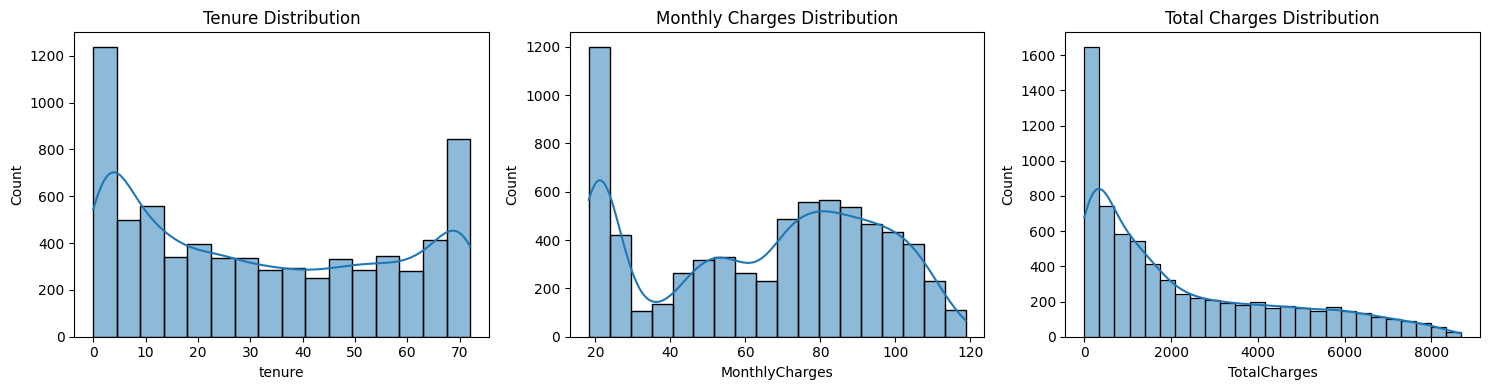

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(df["tenure"], kde=True, ax=axes[0])
axes[0].set_title("Tenure Distribution")

sns.histplot(df["MonthlyCharges"], kde=True, ax=axes[1])
axes[1].set_title("Monthly Charges Distribution")

sns.histplot(df["TotalCharges"], kde=True, ax=axes[2])
axes[2].set_title("Total Charges Distribution")

plt.tight_layout()
plt.show()

### Distribution Insights

The tenure distribution shows a high number of customers with very low tenure, while a significant number of customers have stayed with the company for several years.

MonthlyCharges are spread across a wide range, with more customers concentrated around the middle range.

TotalCharges is strongly right-skewed, with many customers having relatively low total charges and fewer customers having much higher total charges.

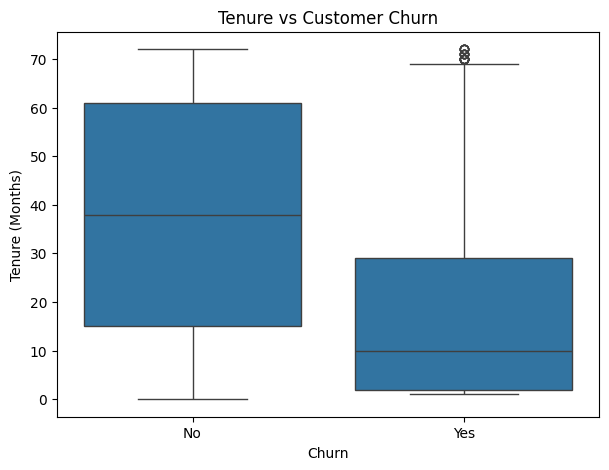

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="Churn", y="tenure")

plt.title("Tenure vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")

plt.show()

### Insight

Customers who churn tend to have a much lower tenure than customers who stay. The median tenure of churned customers is around 10 months, compared with around 38 months for customers who did not churn.

This suggests that customers with shorter relationships with the company are more likely to churn.

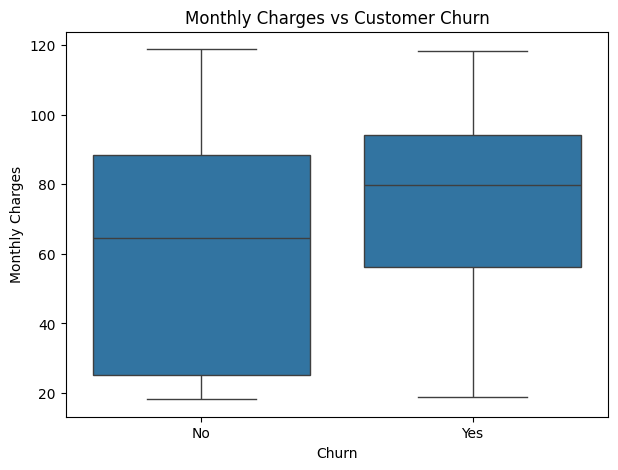

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="Churn", y="MonthlyCharges")

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")

plt.show()

### Insight

Customers who churn tend to have higher monthly charges compared with customers who stay. The median monthly charge for churned customers is around 80, while it is around 65 for customers who did not churn.

This suggests that monthly charges may be related to customer churn, although this relationship does not necessarily mean that higher charges directly cause customers to leave.

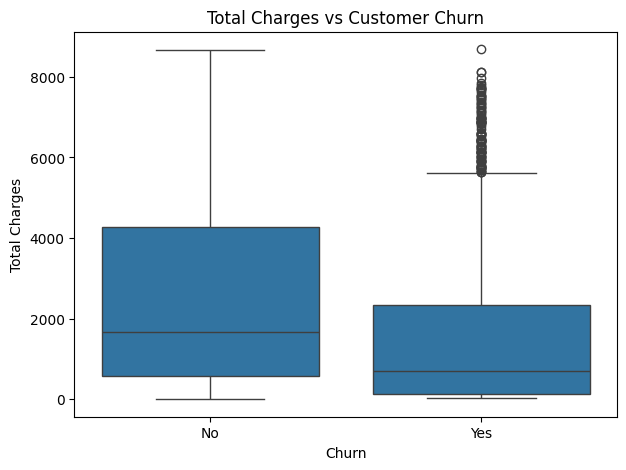

In [ ]:
plt.figure(figsize=(7, 5))

sns.boxplot(data=df, x="Churn", y="TotalCharges")

plt.title("Total Charges vs Customer Churn")
plt.xlabel("Churn")
plt.ylabel("Total Charges")

plt.show()

### Insight

Customers who churn generally have lower TotalCharges compared with customers who stay. The median TotalCharges for churned customers is around 700, while it is around 1,700 for customers who did not churn.

This difference may be related to customer tenure, since customers who leave earlier naturally have lower total charges.

In [ ]:
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(2)

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No,37.57,61.27,2549.91
Yes,17.98,74.44,1531.80


## Categorical Features vs Customer Churn

In [ ]:
categorical_features = [
    "Contract",
    "InternetService",
    "PaymentMethod",
    "OnlineSecurity",
    "TechSupport"
]

for col in categorical_features:
    print(f"\n{col}")

    churn_rate = df.groupby(col)["Churn"].apply(
        lambda x: (x == "Yes").mean() * 100
    )

    print(churn_rate.round(2))


Contract
Contract
Month-to-month    42.71
One year          11.27
Two year           2.83
Name: Churn, dtype: float64

InternetService
InternetService
DSL            18.96
Fiber optic    41.89
No              7.40
Name: Churn, dtype: float64

PaymentMethod
PaymentMethod
Bank transfer (automatic)    16.71
Credit card (automatic)      15.24
Electronic check             45.29
Mailed check                 19.11
Name: Churn, dtype: float64

OnlineSecurity
OnlineSecurity
No                     41.77
No internet service     7.40
Yes                    14.61
Name: Churn, dtype: float64

TechSupport
TechSupport
No                     41.64
No internet service     7.40
Yes                    15.17
Name: Churn, dtype: float64


### Business Insights

- Month-to-month customers have the highest churn rate (42.71%), while two-year contract customers have the lowest (2.83%).
- Fiber optic and electronic check users show relatively higher churn rates.
- Customers without Online Security or Tech Support have significantly higher churn rates.

These features may be useful for predicting customer churn.

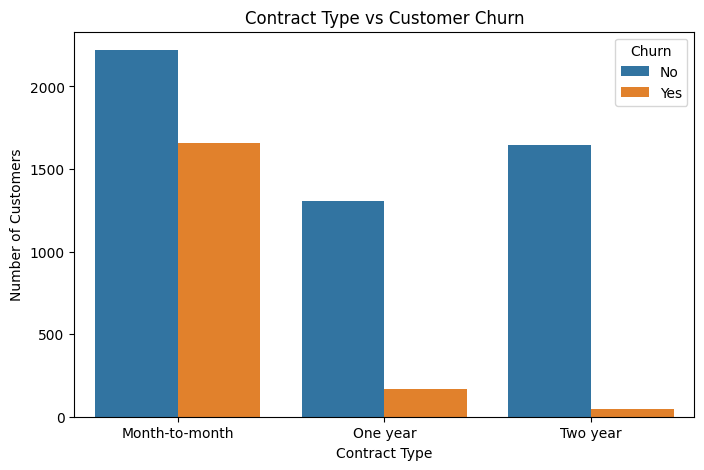

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="Contract", hue="Churn")

plt.title("Contract Type vs Customer Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")

plt.show()

### Insight

Month-to-month contract customers show a much higher churn rate compared with one-year and two-year contract customers.

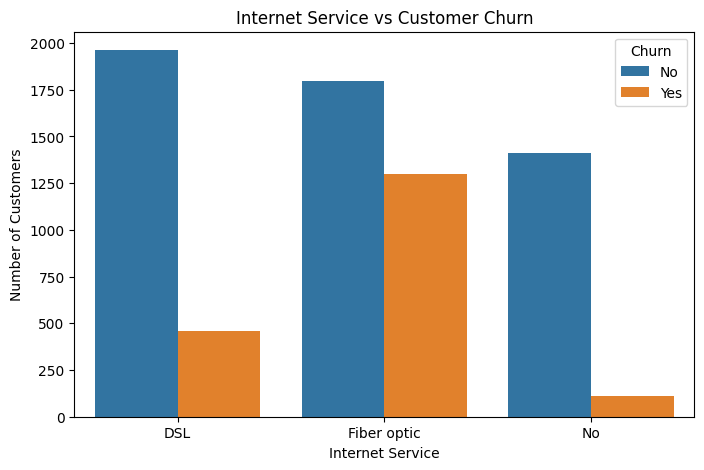

In [ ]:
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x="InternetService", hue="Churn")

plt.title("Internet Service vs Customer Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")

plt.show()

### Insight

Fiber optic customers have a noticeably higher churn rate compared with DSL and customers without internet service.

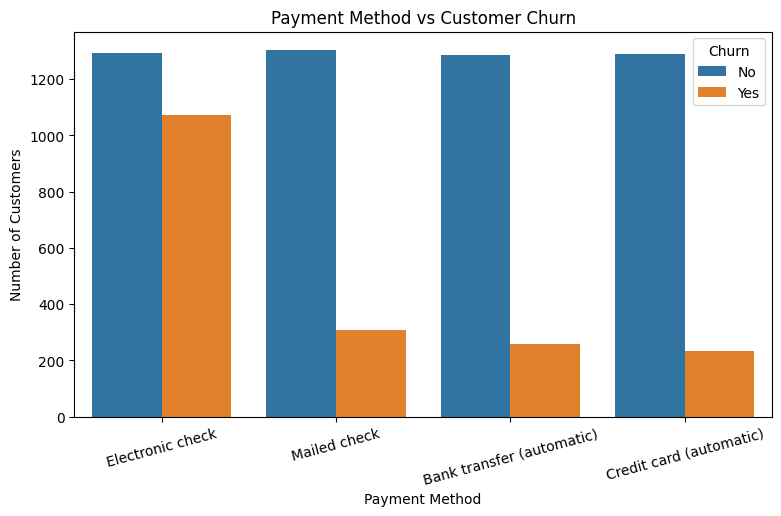

In [ ]:
plt.figure(figsize=(9, 5))

sns.countplot(data=df, x="PaymentMethod", hue="Churn")

plt.title("Payment Method vs Customer Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)

plt.show()

### Insight

Customers using electronic checks have a much higher churn rate compared with other payment methods.

## Correlation Analysis

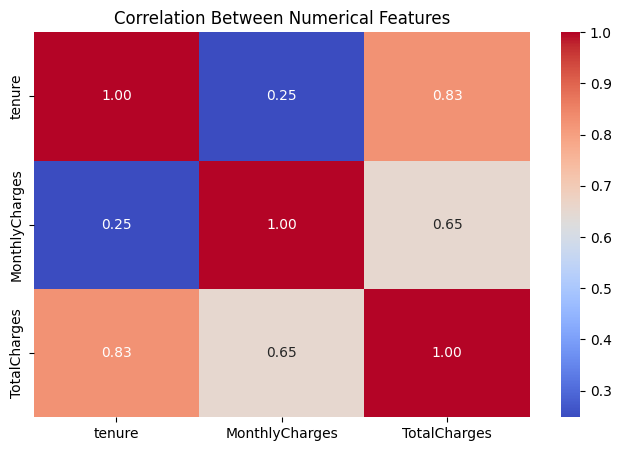

In [ ]:
plt.figure(figsize=(8, 5))

correlation = df[["tenure", "MonthlyCharges", "TotalCharges"]].corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Numerical Features")
plt.show()

### Correlation Insight

Tenure and TotalCharges show a strong positive correlation (0.83), which is expected because customers who stay longer generally accumulate higher total charges.

MonthlyCharges and TotalCharges also show a moderate positive relationship (0.65), while tenure and MonthlyCharges have a weaker relationship (0.25).

## 5. Feature Engineering

In [ ]:
# Feature 1: Customer tenure group
df["tenure_group"] = "Loyal"
df.loc[df["tenure"] <= 36, "tenure_group"] = "Medium"
df.loc[df["tenure"] <= 12, "tenure_group"] = "New"


# Feature 2: High monthly charges
charge_threshold = df["MonthlyCharges"].median()

df["high_charges"] = (
    df["MonthlyCharges"] > charge_threshold
).astype(int)


# Feature 3: Number of services used by the customer
service_columns = [
    "PhoneService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies"
]

df["total_services"] = (
    df[service_columns]
    .apply(lambda row: (row == "Yes").sum(), axis=1)
)


# Check the new features
df[[
    "tenure",
    "tenure_group",
    "MonthlyCharges",
    "high_charges",
    "total_services"
]].head()

,tenure,tenure_group,MonthlyCharges,high_charges,total_services
0,1,New,29.85,0,1
1,34,Medium,56.95,0,3
2,2,New,53.85,0,3
3,45,Loyal,42.30,0,3
4,2,New,70.70,1,1


## 6. Encoding Categorical Variables

In [ ]:
y = df["Churn"].map({"No": 0, "Yes": 1})

In [ ]:
X = df.drop("Churn", axis=1)

In [ ]:
X.select_dtypes(include="object").columns

Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'tenure_group'],
      dtype='object')

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (5634, 22)
Testing data: (1409, 22)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = X_train.select_dtypes(include="object").columns
numeric_cols = X_train.select_dtypes(exclude="object").columns

print("Categorical columns:", list(categorical_cols))
print("Numeric columns:", list(numeric_cols))

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'tenure_group']
Numeric columns: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'high_charges', 'total_services']


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numeric_cols)
    ]
)

In [ ]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (5634, 50)
Encoded testing shape: (1409, 50)


In [ ]:
feature_names = preprocessor.get_feature_names_out()

print("Number of features:", len(feature_names))
print(feature_names)

Number of features: 50
['cat__gender_Female' 'cat__gender_Male' 'cat__Partner_No'
 'cat__Partner_Yes' 'cat__Dependents_No' 'cat__Dependents_Yes'
 'cat__PhoneService_No' 'cat__PhoneService_Yes' 'cat__MultipleLines_No'
 'cat__MultipleLines_No phone service' 'cat__MultipleLines_Yes'
 'cat__InternetService_DSL' 'cat__InternetService_Fiber optic'
 'cat__InternetService_No' 'cat__OnlineSecurity_No'
 'cat__OnlineSecurity_No internet service' 'cat__OnlineSecurity_Yes'
 'cat__OnlineBackup_No' 'cat__OnlineBackup_No internet service'
 'cat__OnlineBackup_Yes' 'cat__DeviceProtection_No'
 'cat__DeviceProtection_No internet service' 'cat__DeviceProtection_Yes'
 'cat__TechSupport_No' 'cat__TechSupport_No internet service'
 'cat__TechSupport_Yes' 'cat__StreamingTV_No'
 'cat__StreamingTV_No internet service' 'cat__StreamingTV_Yes'
 'cat__StreamingMovies_No' 'cat__StreamingMovies_No internet service'
 'cat__StreamingMovies_Yes' 'cat__Contract_Month-to-month'
 'cat__Contract_One year' 'cat__Contract_Two y

## 7. Feature Scaling

In [ ]:
print(type(X_train_encoded))

<class 'numpy.ndarray'>


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_encoded)
X_test_scaled = scaler.transform(X_test_encoded)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Scaled training shape: (5634, 50)
Scaled testing shape: (1409, 50)


## 8. Model Training

###Logistic Regression

In [ ]:
from sklearn.linear_model import LogisticRegression

logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

logistic_model.fit(X_train_scaled, y_train)

y_pred_lr = logistic_model.predict(X_test_scaled)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


### Logistic Regression Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

print("Accuracy:", round(accuracy_score(y_test, y_pred_lr), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_lr))

Accuracy: 0.8013

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.90      0.87      1035
           1       0.65      0.53      0.59       374

    accuracy                           0.80      1409
   macro avg       0.75      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



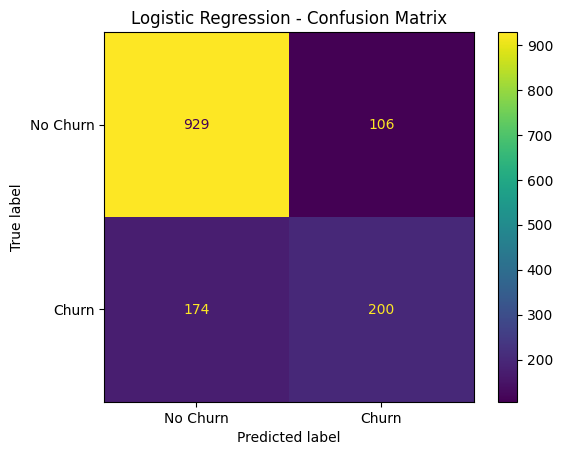

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=["No Churn", "Churn"]
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### Confusion Matrix Insight

The model correctly identifies most non-churning customers, but it misses a significant number of actual churners. Out of 374 actual churn customers, 200 were correctly identified while 174 were missed.

Therefore, improving recall for the churn class is important for this business problem.

###Balancing

In [ ]:
from imblearn.over_sampling import RandomOverSampler

oversampler = RandomOverSampler(random_state=42)

X_train_balanced, y_train_balanced = oversampler.fit_resample(
    X_train_encoded,
    y_train
)

print("Before balancing:")
print(y_train.value_counts())

print("\nAfter balancing:")
print(y_train_balanced.value_counts())

Before balancing:
Churn
0    4139
1    1495
Name: count, dtype: int64

After balancing:
Churn
0    4139
1    4139
Name: count, dtype: int64


In [ ]:
X_train_balanced
y_train_balanced

,Churn
0,0
1,0
2,0
3,0
4,0
...,...
8273,1
8274,1
8275,1
8276,1


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler_balanced = StandardScaler()

X_train_balanced_scaled = scaler_balanced.fit_transform(X_train_balanced)
X_test_balanced_scaled = scaler_balanced.transform(X_test_encoded)

print("Balanced training shape:", X_train_balanced_scaled.shape)
print("Test shape:", X_test_balanced_scaled.shape)

Balanced training shape: (8278, 50)
Test shape: (1409, 50)


### Logistic Regression with Balanced Data

In [ ]:
from sklearn.linear_model import LogisticRegression

balanced_logistic = LogisticRegression(
    max_iter=1000,
    random_state=42
)

balanced_logistic.fit(
    X_train_balanced_scaled,
    y_train_balanced
)

y_pred_balanced_lr = balanced_logistic.predict(
    X_test_balanced_scaled
)

print("Balanced Logistic Regression trained successfully.")

Balanced Logistic Regression trained successfully.


### Balanced Logistic Regression Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_balanced_lr), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced_lr))

Accuracy: 0.7339

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.71      0.80      1035
           1       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.70      1409
weighted avg       0.80      0.73      0.75      1409



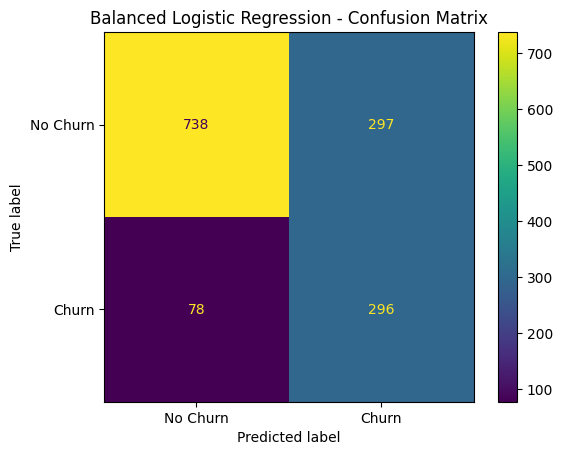

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced_lr,
    display_labels=["No Churn", "Churn"]
)

plt.title("Balanced Logistic Regression - Confusion Matrix")
plt.show()

### Confusion Matrix Insight

After balancing, the model identifies significantly more actual churn customers. However, it also produces more false churn predictions. This shows the trade-off between improving churn recall and maintaining precision.

###Decision Tree

In [ ]:
from sklearn.tree import DecisionTreeClassifier

decision_tree = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

decision_tree.fit(X_train_encoded, y_train)

y_pred_dt = decision_tree.predict(X_test_encoded)

print("Decision Tree trained successfully.")

Decision Tree trained successfully.


### Decision Tree Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(accuracy_score(y_test, y_pred_dt), 4))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

Accuracy: 0.7984

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.87      1035
           1       0.63      0.57      0.60       374

    accuracy                           0.80      1409
   macro avg       0.74      0.72      0.73      1409
weighted avg       0.79      0.80      0.79      1409



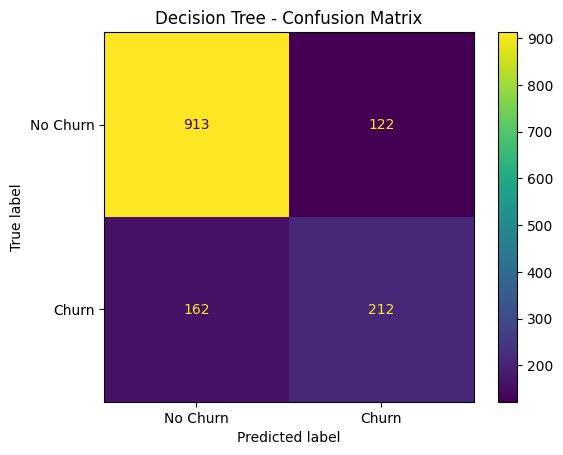

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=["No Churn", "Churn"]
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

### Confusion Matrix Insight

The Decision Tree identifies 212 out of 374 actual churn customers. It improves churn detection compared with Logistic Regression, but still misses 162 churn customers.

### Decision Tree with Balanced Data

In [ ]:
from sklearn.tree import DecisionTreeClassifier

balanced_dt = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

balanced_dt.fit(
    X_train_balanced,
    y_train_balanced
)

y_pred_balanced_dt = balanced_dt.predict(
    X_test_encoded
)

print("Balanced Decision Tree trained successfully.")

Balanced Decision Tree trained successfully.


### Balanced Decision Tree Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_balanced_dt), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced_dt))

Accuracy: 0.7417

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.71      0.80      1035
           1       0.51      0.82      0.63       374

    accuracy                           0.74      1409
   macro avg       0.71      0.77      0.71      1409
weighted avg       0.81      0.74      0.76      1409



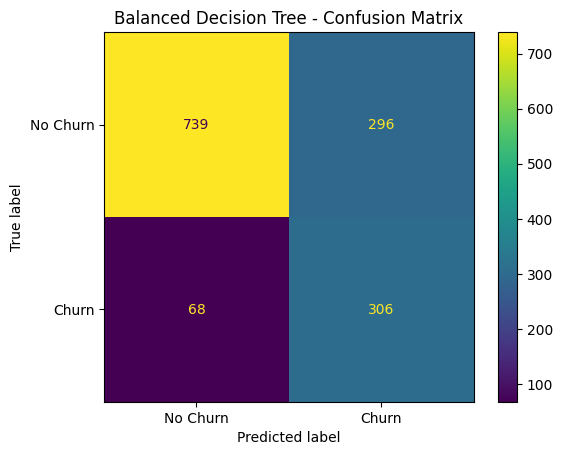

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced_dt,
    display_labels=["No Churn", "Churn"]
)

plt.title("Balanced Decision Tree - Confusion Matrix")
plt.show()

### Confusion Matrix Insight

After balancing, the Decision Tree identifies most actual churn customers, achieving around 82% recall. However, it also produces more false churn predictions, showing a trade-off between recall and precision.

## 9. Random Forest

In [ ]:
from sklearn.ensemble import RandomForestClassifier

random_forest = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

random_forest.fit(
    X_train_encoded,
    y_train
)

y_pred_rf = random_forest.predict(X_test_encoded)

print("Random Forest trained successfully.")

Random Forest trained successfully.


### Random Forest Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_rf), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_rf))

Accuracy: 0.8013

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.67      0.51      0.57       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



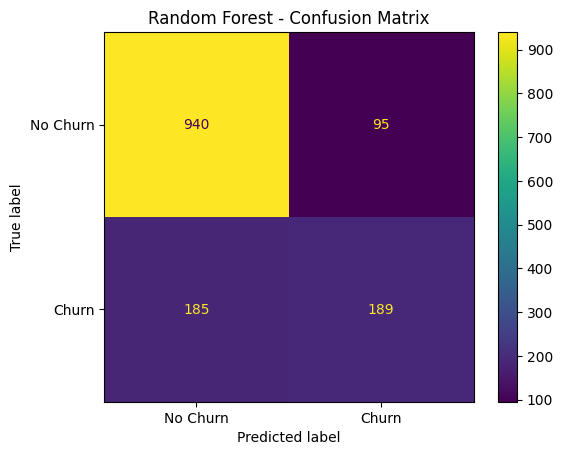

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["No Churn", "Churn"]
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

### Random Forest with Balanced Data

In [ ]:
from sklearn.ensemble import RandomForestClassifier

balanced_rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    random_state=42
)

balanced_rf.fit(
    X_train_balanced,
    y_train_balanced
)

y_pred_balanced_rf = balanced_rf.predict(X_test_encoded)

print("Balanced Random Forest trained successfully.")

Balanced Random Forest trained successfully.


### Balanced Random Forest Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_balanced_rf), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced_rf))

Accuracy: 0.758

Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.75      0.82      1035
           1       0.53      0.78      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.76      0.72      1409
weighted avg       0.80      0.76      0.77      1409



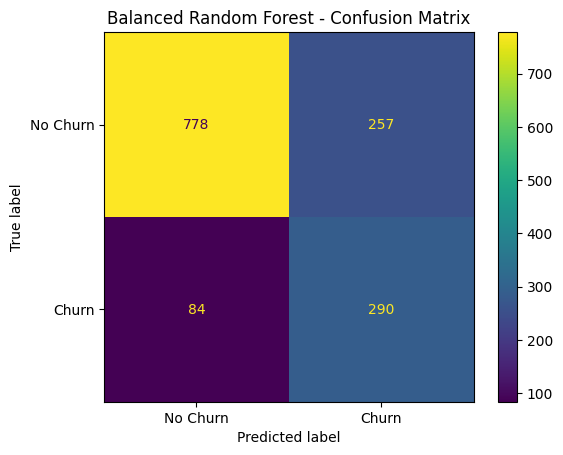

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced_rf,
    display_labels=["No Churn", "Churn"]
)

plt.title("Balanced Random Forest - Confusion Matrix")
plt.show()

### Confusion Matrix Insight

After balancing, the Random Forest identifies significantly more actual churn customers, with around 78% churn recall. However, the number of false churn predictions also increases.

##  XGBoost

### XGBoost Training

In [ ]:
from xgboost import XGBClassifier

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss"
)

xgb_model.fit(
    X_train_encoded,
    y_train
)

y_pred_xgb = xgb_model.predict(X_test_encoded)

print("XGBoost trained successfully.")

XGBoost trained successfully.


### XGBoost Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_xgb), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_xgb))

Accuracy: 0.8077

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.91      0.87      1035
           1       0.68      0.53      0.59       374

    accuracy                           0.81      1409
   macro avg       0.76      0.72      0.73      1409
weighted avg       0.80      0.81      0.80      1409



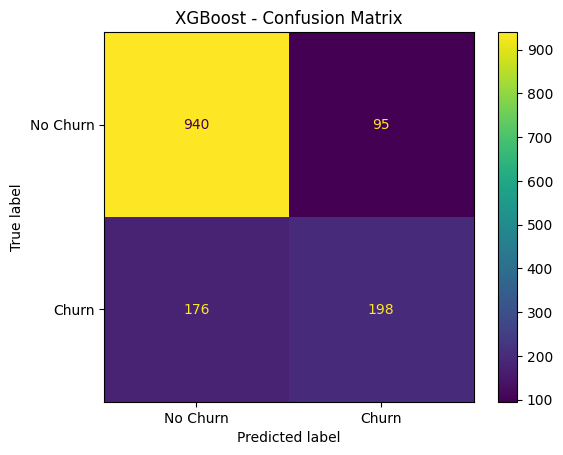

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    display_labels=["No Churn", "Churn"]
)

plt.title("XGBoost - Confusion Matrix")
plt.show()

### Confusion Matrix Insight

The XGBoost model correctly identifies most non-churn customers, but it misses a considerable number of actual churn customers. Its churn recall is around 53%, so balancing may help improve churn detection.

### XGBoost with Balanced Data

In [ ]:
from xgboost import XGBClassifier

balanced_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    random_state=42,
    eval_metric="logloss"
)

balanced_xgb.fit(
    X_train_balanced,
    y_train_balanced
)

y_pred_balanced_xgb = balanced_xgb.predict(X_test_encoded)

print("Balanced XGBoost trained successfully.")

Balanced XGBoost trained successfully.


### Balanced XGBoost Evaluation

In [ ]:
from sklearn.metrics import accuracy_score, classification_report

print("Accuracy:", round(
    accuracy_score(y_test, y_pred_balanced_xgb), 4
))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced_xgb))

Accuracy: 0.7537

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.74      0.82      1035
           1       0.52      0.79      0.63       374

    accuracy                           0.75      1409
   macro avg       0.71      0.76      0.72      1409
weighted avg       0.80      0.75      0.77      1409



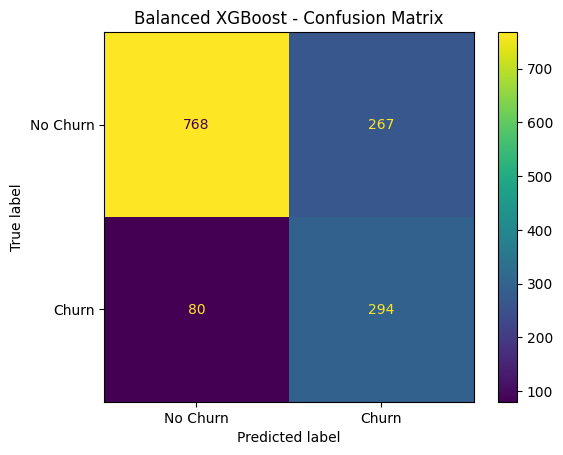

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_balanced_xgb,
    display_labels=["No Churn", "Churn"]
)

plt.title("Balanced XGBoost - Confusion Matrix")
plt.show()

### Confusion Matrix Insight

After balancing, XGBoost identifies most actual churn customers, achieving around 79% recall. However, it also produces more false churn predictions, showing a trade-off between recall and precision.

## 9. Model Comparison

In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import pandas as pd

models = {
    "Logistic Regression": y_pred_lr,
    "Balanced Logistic Regression": y_pred_balanced_lr,
    "Decision Tree": y_pred_dt,
    "Balanced Decision Tree": y_pred_balanced_dt,
    "Random Forest": y_pred_rf,
    "Balanced Random Forest": y_pred_balanced_rf,
    "XGBoost": y_pred_xgb,
    "Balanced XGBoost": y_pred_balanced_xgb
}

results = []

for name, predictions in models.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions)
    })

comparison_df = pd.DataFrame(results)

comparison_df.round(4)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8013,0.6536,0.5348,0.5882
1,Balanced Logistic Regression,0.7339,0.4992,0.7914,0.6122
2,Decision Tree,0.7984,0.6347,0.5668,0.5989
3,Balanced Decision Tree,0.7417,0.5083,0.8182,0.6270
4,Random Forest,0.8013,0.6655,0.5053,0.5745
5,Balanced Random Forest,0.7580,0.5302,0.7754,0.6298
6,XGBoost,0.8077,0.6758,0.5294,0.5937
7,Balanced XGBoost,0.7537,0.5241,0.7861,0.6289


## 10. Final Model Selection

Based on the model comparison, Balanced Random Forest is selected as the final model.

It achieved the highest F1-score of 62.98% among the evaluated models while maintaining a strong churn recall of 77.54%.

Although the Balanced Decision Tree achieved a slightly higher recall, Balanced Random Forest provided a better overall balance between precision and recall.

In [ ]:
final_model = balanced_rf

print("Final model: Balanced Random Forest")

Final model: Balanced Random Forest


In [ ]:
preprocessor

ColumnTransformer(transformers=[('cat', OneHotEncoder(handle_unknown='ignore'),
                                 Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling', 'PaymentMethod', 'tenure_group'],
      dtype='object')),
                                ('num', 'passthrough',
                                 Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges',
       'high_charges', 'total_services'],
      dtype='object'))])

In [ ]:
X_train_encoded

array([[0.00000e+00, 1.00000e+00, 1.00000e+00, ..., 1.70165e+03,
        0.00000e+00, 3.00000e+00],
       [0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 1.15155e+03,
        1.00000e+00, 2.00000e+00],
       [0.00000e+00, 1.00000e+00, 0.00000e+00, ..., 5.90350e+02,
        0.00000e+00, 3.00000e+00],
       ...,
       [1.00000e+00, 0.00000e+00, 1.00000e+00, ..., 2.66020e+03,
        1.00000e+00, 5.00000e+00],
       [1.00000e+00, 0.00000e+00, 0.00000e+00, ..., 4.82800e+02,
        0.00000e+00, 1.00000e+00],
       [0.00000e+00, 1.00000e+00, 1.00000e+00, ..., 1.09300e+02,
        0.00000e+00, 1.00000e+00]])

### Feature Importance

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

feature_names = preprocessor.get_feature_names_out()

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(10)

,Feature,Importance
32,cat__Contract_Month-to-month,0.133215
45,num__tenure,0.089561
47,num__TotalCharges,0.080594
34,cat__Contract_Two year,0.077884
14,cat__OnlineSecurity_No,0.059484
23,cat__TechSupport_No,0.057061
46,num__MonthlyCharges,0.056952
12,cat__InternetService_Fiber optic,0.056821
39,cat__PaymentMethod_Electronic check,0.039440
43,cat__tenure_group_New,0.039115


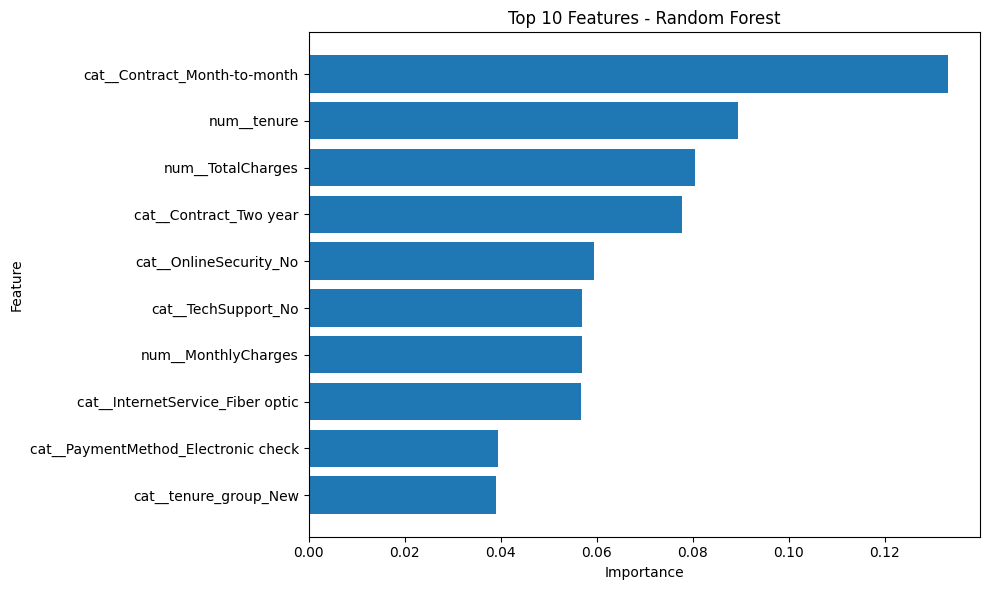

In [ ]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features - Random Forest")

plt.tight_layout()
plt.show()

### Feature Importance Insight

The feature importance analysis shows that contract type is the most influential feature in predicting customer churn. Month-to-month contracts have the highest importance, followed by customer tenure and total charges.

Other important factors include online security, technical support, monthly charges, internet service type, payment method, and whether the customer is new.

These findings are consistent with the EDA, where customers with shorter tenure, month-to-month contracts, and higher monthly charges showed higher churn tendencies.

## 11. SHAP Explainability

In [ ]:
!pip install shap -q

import shap
import numpy as np
import matplotlib.pyplot as plt

print("SHAP imported successfully.")

SHAP imported successfully.


In [ ]:
# Create SHAP explainer for the final Random Forest model
explainer = shap.TreeExplainer(final_model)

# Calculate SHAP values on a sample of test data
X_shap = X_test_encoded[:200]
shap_values = explainer.shap_values(X_shap)

print("SHAP values calculated successfully.")
print("SHAP values type:", type(shap_values))

SHAP values calculated successfully.
SHAP values type: <class 'numpy.ndarray'>


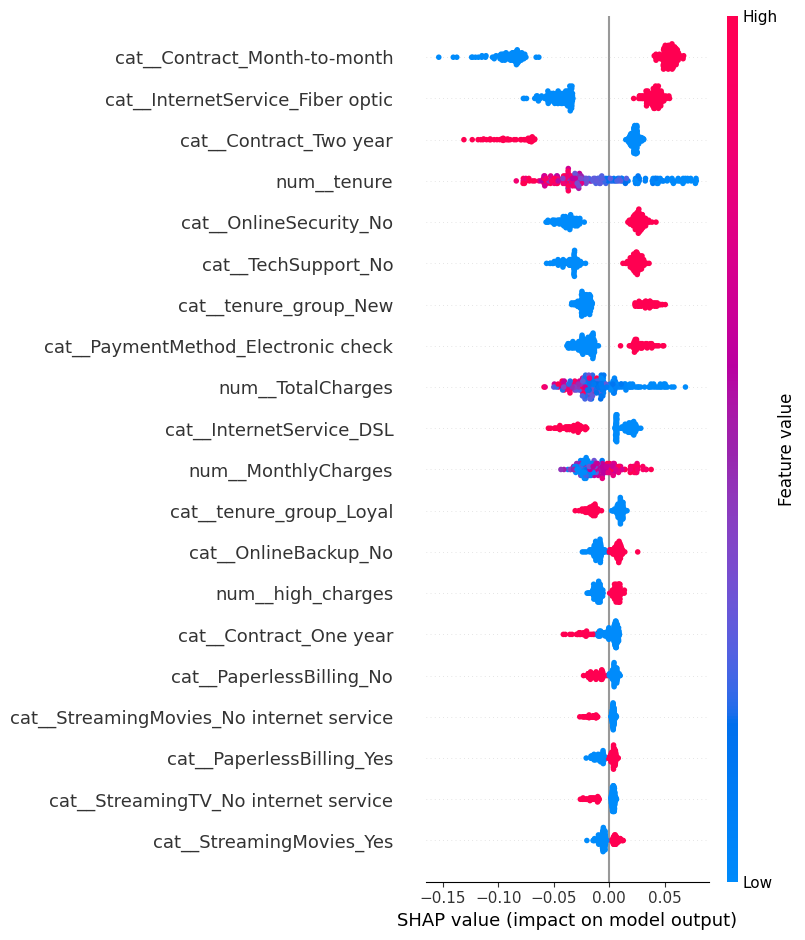

In [ ]:
# Select SHAP values for the Churn class (class 1)
shap_values_churn = shap_values[:, :, 1]

shap.summary_plot(
    shap_values_churn,
    X_shap,
    feature_names=feature_names,
    show=True
)

### SHAP Explainability Insight

The SHAP analysis shows that contract type, internet service, tenure, online security, and technical support are among the most influential factors in churn prediction.

Month-to-month contracts and the absence of online security or technical support tend to push predictions toward churn, while longer contracts and higher customer tenure generally reduce churn risk.

SHAP provides additional interpretability compared with traditional feature importance because it shows not only which features are important, but also how their values influence individual model predictions.

## 12. Saving Final Model

In [ ]:
import joblib

# Save final model
joblib.dump(final_model, "final_random_forest.pkl")

# Save preprocessing pipeline
joblib.dump(preprocessor, "preprocessor.pkl")

print("Final model saved successfully.")
print("Preprocessor saved successfully.")

Final model saved successfully.
Preprocessor saved successfully.


In [ ]:
from google.colab import files

files.download("final_random_forest.pkl")
files.download("preprocessor.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from google.colab import files

files.download("final_random_forest.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. Model Prediction Verification

### Testing Predictions on Sample Test Data

In [ ]:
sample_predictions = final_model.predict(X_test_encoded[:5])

verification = pd.DataFrame({
    "Actual": y_test.iloc[:5].values,
    "Predicted": sample_predictions
})

verification["Result"] = verification.apply(
    lambda row: "Correct" if row["Actual"] == row["Predicted"] else "Wrong",
    axis=1
)

verification

,Actual,Predicted,Result
0,0,0,Correct
1,0,1,Wrong
2,0,0,Correct
3,0,1,Wrong
4,0,0,Correct


In [ ]:
# Select 5 actual churn customers from the test set
churn_indices = y_test[y_test == 1].index[:5]

churn_predictions = final_model.predict(
    X_test_encoded[y_test.index.get_indexer(churn_indices)]
)

verification_churn = pd.DataFrame({
    "Actual": y_test.loc[churn_indices].values,
    "Predicted": churn_predictions
})

verification_churn["Result"] = verification_churn.apply(
    lambda row: "Correct" if row["Actual"] == row["Predicted"] else "Wrong",
    axis=1
)

verification_churn

,Actual,Predicted,Result
0,1,1,Correct
1,1,1,Correct
2,1,1,Correct
3,1,1,Correct
4,1,1,Correct


### Prediction Verification Insight

The final model was tested on sample customers from the unseen test dataset. It correctly identified all five selected churn customers in this sample, demonstrating that the model can successfully predict churn for individual customers. Overall model performance is evaluated using the complete test dataset through accuracy, precision, recall, and F1-score.